# Irish Property Price Trends, 2010–2026

**Author:** Maksym Redchenko · **Student number:** C00302240
**Module:** Data Science & Machine Learning 1, Continuous Assessment Portfolio, Project 1
**GitHub:** https://github.com/S5in/Data-Science-and-Machine-Learning

This notebook studies how Irish residential property prices have changed since 2010, and whether a regression model trained on past prices can forecast recent prices. It follows the CRISP-DM process covered in lectures:

1. Business understanding
2. Setup
3. Data understanding
4. Data preparation
5. Exploratory analysis
6. Modelling the national trend
7. County-level models
8. Deployment
9. Conclusion

In [1]:
# Author: Maksym Redchenko
# Student number: C00302240
# Project 1: Irish Property Price Trends (Data Science & ML 1 CA portfolio)

## 1. Business understanding

**Question.** How well can a regression model trained on past Irish house prices forecast how prices change over time, nationally and by county?

**Why it matters.** Housing is one of the largest costs for anyone living in Ireland. Buyers, renters, lenders and policymakers all care about where prices are heading.

**Success criteria.** Models are trained on sales up to the end of 2023 and tested on 2024–2026, a period they have never seen. They are judged by forecast error in euro (RMSE and MAE) and by R².

**Type of analytics.** The lectures (Chapter 5) describe several types of analytics. This project uses two:

- **Descriptive** (Sections 3–5): what happened to Irish house prices between 2010 and 2026?
- **Predictive** (Sections 6–7): can past prices forecast future prices?

It touches on **diagnostic** analytics (why something happened) only briefly, for example the new-home premium in Section 5.3. Explaining *why* prices moved would need data the register doesn't contain, such as interest rates, incomes or housing supply.


## 2. Setup

All libraries are imported here, and the settings used throughout the notebook are defined as constants so they are easy to find and change.

In [2]:
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import (mean_squared_error, mean_absolute_error,
                             mean_absolute_percentage_error, r2_score)
from sklearn.exceptions import ConvergenceWarning
from sklearn.base import BaseEstimator, TransformerMixin
import warnings

# --- Data location -------------------------------------------------------
# The raw data is kept in the zip file at the root of the repository,
# so it does not need to be extracted or duplicated.
DATA_ZIP = Path("..") / "archive.zip"
CSV_NAME = "property_price_register.csv"

# --- Cleaning settings (justified in Section 4) ---------------------------
VAT_RATE_NEW_HOMES = 0.135   # Irish VAT rate on new residential property
MIN_PRICE = 20_000           # below this, sales are unlikely to be a full dwelling
MAX_PRICE = 3_000_000        # above this, many records are bulk/multi-unit purchases

# --- Modelling settings (Section 6) ---------------------------------------
TEST_START = "2024-01-01"     # train on 2010-2023, test on Jan 2024 onwards
RECOVERY_START = "2014-01-01" # start of the post-crash recovery (see Section 5.1)
CV_SPLITS = 5                 # folds for time-series cross-validation

# --- Plot style -----------------------------------------------------------
plt.rcParams.update({
    "figure.figsize": (11, 4.5),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

In [3]:
def euro_formatter(value, _position):
    """Format an axis tick as euro, e.g. 250000 -> '€250k'."""
    if abs(value) >= 1_000_000:
        return f"€{value / 1_000_000:.1f}M"
    return f"€{value / 1_000:.0f}k"


def format_euro_axis(ax, axis="y"):
    """Apply the euro formatter to the y (default) or x axis of a plot."""
    target = ax.yaxis if axis == "y" else ax.xaxis
    target.set_major_formatter(FuncFormatter(euro_formatter))

## 3. Data understanding

### 3.1 Loading the data

The data is the **Residential Property Price Register**, published by the Property Services Regulatory Authority (PSRA, https://www.propertypriceregister.ie). Every residential sale in Ireland must be recorded in it. The CSV is read directly out of the zip file.

In [4]:
def load_register(zip_path, csv_name):
    """Read the Property Price Register CSV from inside a zip archive."""
    with zipfile.ZipFile(zip_path) as archive:
        with archive.open(csv_name) as csv_file:
            data = pd.read_csv(
                csv_file,
                parse_dates=["date_of_sale"],
                dtype={"eircode": "string", "property_size": "string"},
                low_memory=False,
            )
    return data


raw = load_register(DATA_ZIP, CSV_NAME)
print(f"{len(raw):,} sales, {raw.shape[1]} columns")
print(f"Date range: {raw['date_of_sale'].min():%d %b %Y} to {raw['date_of_sale'].max():%d %b %Y}")
raw.head()

807,936 sales, 9 columns
Date range: 01 Jan 2010 to 25 Sep 2026


,date_of_sale,address,county,eircode,price_eur,not_full_market_price,vat_exclusive,description,property_size
0,2010-01-01,"5 Braemor Drive, Churchtown, Co.Dublin",Dublin,<NA>,343000.0,False,False,Second-Hand Dwelling house /Apartment,<NA>
1,2010-01-03,"134 Ashewood Walk, Summerhill Lane, Portlaoise",Laois,<NA>,185000.0,False,True,New Dwelling house /Apartment,greater than or equal to 38 sq metres and less...
2,2010-01-04,"59 ormond keep, nenagh",Tipperary,<NA>,128000.0,False,False,Second-Hand Dwelling house /Apartment,<NA>
3,2010-01-04,"66 Rory O'Connor Place, Arklow",Wicklow,<NA>,145000.0,False,False,Second-Hand Dwelling house /Apartment,<NA>
4,2010-01-04,"78 Sundays Well Road, Cork",Cork,<NA>,510000.0,False,False,Second-Hand Dwelling house /Apartment,<NA>


In [5]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 807936 entries, 0 to 807935
Data columns (total 9 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   date_of_sale           807936 non-null  datetime64[us]
 1   address                807936 non-null  str           
 2   county                 807936 non-null  str           
 3   eircode                251432 non-null  string        
 4   price_eur              807936 non-null  float64       
 5   not_full_market_price  807936 non-null  bool          
 6   vat_exclusive          807936 non-null  bool          
 7   description            807936 non-null  str           
 8   property_size          52608 non-null   string        
dtypes: bool(2), datetime64[us](1), float64(1), str(3), string(2)
memory usage: 44.7 MB


### 3.2 Missing values

In [6]:
missing = (raw.isna().mean() * 100).round(1).sort_values(ascending=False)
missing.to_frame("% missing")

,% missing
property_size,93.5
eircode,68.9
date_of_sale,0.0
county,0.0
address,0.0
price_eur,0.0
not_full_market_price,0.0
vat_exclusive,0.0
description,0.0


**Observation.** `property_size` is missing for about 93% of sales and `eircode` for about 69%, so neither is usable as a feature across the whole period. Every other column is complete. The analysis uses date, county, price, the two flags and the description.

### 3.3 Property description

In [7]:
raw["description"].value_counts()

description
Second-Hand Dwelling house /Apartment    663246
New Dwelling house /Apartment            144641
Teach/Árasán Cónaithe Atháimhe               45
Teach/Árasán Cónaithe Nua                     3
Teach/?ras?n C?naithe Nua                     1
Name: count, dtype: int64

**Observation.** There are really only two categories, new and second-hand. A few records are in Irish (*Teach/Árasán Cónaithe Nua* = new dwelling, *Atháimhe* = second-hand), and one has a garbled character encoding. These are mapped to the English categories in Section 4.

### 3.4 Price distribution

In [8]:
raw["price_eur"].describe(percentiles=[0.001, 0.01, 0.5, 0.99, 0.999]).apply(lambda v: f"{v:,.0f}")

count        807,936
mean         322,169
std        1,317,879
min            5,001
0.1%           8,830
1%            25,000
50%          245,000
99%        1,424,475
99.9%      6,250,000
max      387,665,198
Name: price_eur, dtype: str

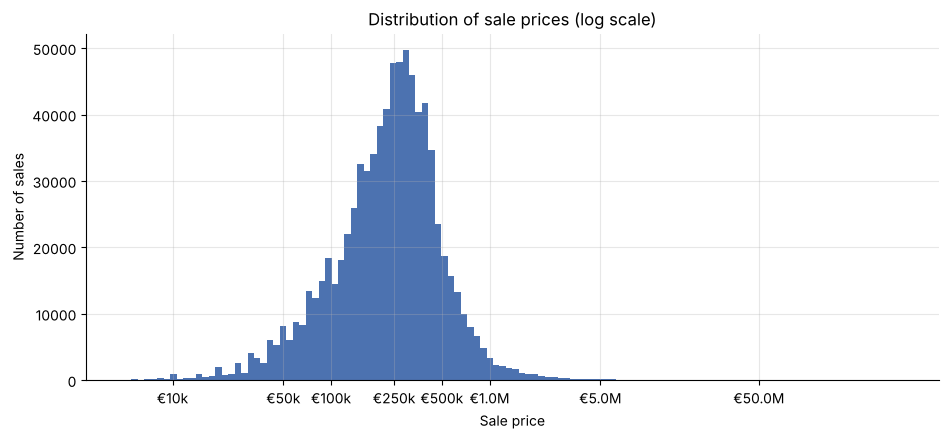

In [9]:
fig, ax = plt.subplots()
ax.hist(np.log10(raw["price_eur"]), bins=120, color="#4C72B0")
ticks = [10_000, 50_000, 100_000, 250_000, 500_000, 1_000_000, 5_000_000, 50_000_000]
ax.set_xticks(np.log10(ticks))
ax.set_xticklabels([euro_formatter(t, None) for t in ticks])
ax.set_title("Distribution of sale prices (log scale)")
ax.set_xlabel("Sale price")
ax.set_ylabel("Number of sales")
plt.show()

**Observation.** Prices are strongly right-skewed. A log scale is needed to see the shape. Most sales are between about €100k and €500k, but the extremes range from €5,000 to over €380 million. Records like that are not ordinary home sales, so they are handled in Section 4. Because the analysis is built on **medians**, a small number of extreme values has little effect, but removing obvious errors is still good practice.

### 3.5 Market-price and VAT flags

In [10]:
print(f"Not full market price: {raw['not_full_market_price'].mean():.1%} of sales")
pd.crosstab(raw["description"], raw["vat_exclusive"], margins=True)

Not full market price: 5.1% of sales


vat_exclusive,False,True,All
description,,,
New Dwelling house /Apartment,2373,142268,144641
Second-Hand Dwelling house /Apartment,663246,0,663246
Teach/?ras?n C?naithe Nua,0,1,1
Teach/Árasán Cónaithe Atháimhe,45,0,45
Teach/Árasán Cónaithe Nua,0,3,3
All,665664,142272,807936


**Observation.** About 5% of sales are flagged as *not full market price* (for example transfers between family members), so they don't reflect the market. Almost every **new** dwelling is recorded *excluding VAT*, while second-hand sales are recorded with no VAT. Comparing the two directly would understate new-home prices, so VAT is added back in Section 4.

### 3.6 Sales volume over time

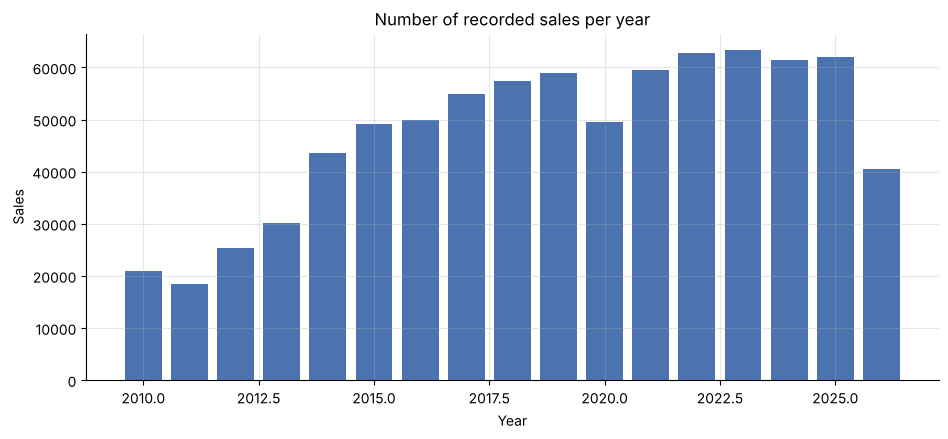

In [11]:
sales_per_year = raw.groupby(raw["date_of_sale"].dt.year).size()

fig, ax = plt.subplots()
ax.bar(sales_per_year.index, sales_per_year.values, color="#4C72B0")
ax.set_title("Number of recorded sales per year")
ax.set_xlabel("Year")
ax.set_ylabel("Sales")
plt.show()

**Observation.** Sales volume was lowest in 2011 and rose until 2019. It dipped in 2020 (the COVID-19 lockdowns) and has stayed around 60,000 a year since. 2026 is only a partial year (data ends in September).

### 3.7 Data formats and storage

The zip file contains the same records in three formats. The Data Modelling lecture compared formats for structured data, so this is a useful practical example.

In [12]:
def describe_archive(zip_path):
    """List each file in a zip with its full and compressed size in MB."""
    with zipfile.ZipFile(zip_path) as archive:
        rows = [{"file": info.filename,
                 "format": Path(info.filename).suffix.lstrip(".").upper(),
                 "size (MB)": info.file_size / 1e6,
                 "compressed in zip (MB)": info.compress_size / 1e6}
                for info in archive.infolist()]
    return pd.DataFrame(rows).set_index("file")


describe_archive(DATA_ZIP).style.format({"size (MB)": "{:.0f}", "compressed in zip (MB)": "{:.0f}"})

,format,size (MB),compressed in zip (MB)
file,,,
property_price_register.csv,CSV,99,18
property_price_register.json,JSON,224,22
property_price_register.parquet,PARQUET,24,21


**Observation.** The same 807,936 records take very different amounts of space:

| Format | Type | Notes |
|---|---|---|
| **JSON** | Text, one object per record | The largest, because every record repeats every field name (`"county": …`, `"price_eur": …`). Easy for web APIs and humans to read, but wasteful for big tables. |
| **CSV** | Text, one row per record | Field names appear once in the header. Readable in any tool, including Excel, and non-proprietary. |
| **Parquet** | Binary, column-oriented | The smallest. Stores each column together and compresses it, and keeps data types (dates, booleans). Designed for analytics on large datasets. |

Once zipped, all three are a similar size (about 18–22 MB), because zip compression removes most of the repetition in the text formats.

**Why CSV was used here.** It needs no extra library (Parquet needs `pyarrow`), it can be read straight from the zip, and it can be opened and checked in any tool. Loading takes a few seconds, which is acceptable for a dataset this size. For a much larger dataset, or one that is reloaded often, Parquet would be the better choice.

The data is **structured**: every record has the same fields, so it fits naturally into a table (pandas DataFrame) or a relational database table.

### 3.8 Open data, licence and provenance

**Publisher and legal basis.** The register is produced by the Property Services Regulatory Authority (PSRA) under section 86 of the Property Services (Regulation) Act 2011. It records the date, price and address of residential properties bought in Ireland since 2010, **as declared to the Revenue Commissioners for stamp duty**. Prices are the declared transaction prices, not valuations. The PSRA states that the register is *not* a property price index.

**Licence.** The PSRA publishes the register on data.gov.ie under the **Creative Commons Attribution 4.0 (CC BY 4.0)** licence. The data can be reused, including for this project, as long as the source is credited (see References).

**Open data rating.** On Tim Berners-Lee's 5-star open data scale from the lectures, the register is **3-star** open data: it has an open licence (★), is machine-readable structured data (★★) and is in a non-proprietary format like CSV (★★★). It doesn't reach 4 or 5 stars, because it doesn't use URIs or link to other datasets (for example, county codes aren't linked to official geographic data).

**Provenance.** The copy used here was downloaded as a pre-packaged zip with CSV, JSON and Parquet versions of the full register, up to 25 September 2026. The record count, date range and fields match the PSRA register. Because it is a re-packaged copy, the results should be re-checked against the official PSRA download before being relied on.

### 3.9 Data quality summary

CRISP-DM's *Data Understanding* phase ends with verifying data quality. The table below summarises the issues found above, measured on the raw data, and how each is handled in Section 4.

In [13]:
def data_quality_report(data):
    """Summarise data quality issues in the raw register, one row per check."""
    n = len(data)
    duplicates = data.duplicated(subset=["address", "date_of_sale", "price_eur"]).sum()
    extreme = (~data["price_eur"].between(MIN_PRICE, MAX_PRICE)).sum()
    checks = [
        ("Completeness", "property_size missing", data["property_size"].isna().sum(), "Column not used"),
        ("Completeness", "eircode missing", data["eircode"].isna().sum(), "Column not used"),
        ("Uniqueness", "Duplicate sales (same address, date, price)", duplicates, "Removed"),
        ("Validity", f"Price outside €{MIN_PRICE:,}–€{MAX_PRICE:,}", extreme, "Removed"),
        ("Validity", "Not full market price", data["not_full_market_price"].sum(), "Removed"),
        ("Consistency", "Description variants (Irish / garbled text)",
         (~data["description"].str.startswith(("New", "Second"))).sum(), "Mapped to New / Second-hand"),
        ("Consistency", "New homes recorded excluding VAT", data["vat_exclusive"].sum(), "13.5% VAT added back"),
    ]
    report = pd.DataFrame(checks, columns=["dimension", "check", "records", "action"])
    report["% of records"] = report["records"] / n
    return report


data_quality_report(raw).style.format({"records": "{:,}", "% of records": "{:.2%}"})

,dimension,check,records,action,% of records
0,Completeness,property_size missing,"755,328",Column not used,93.49%
1,Completeness,eircode missing,"556,504",Column not used,68.88%
2,Uniqueness,"Duplicate sales (same address, date, price)",90,Removed,0.01%
3,Validity,"Price outside €20,000–€3,000,000","6,747",Removed,0.84%
4,Validity,Not full market price,"40,971",Removed,5.07%
5,Consistency,Description variants (Irish / garbled text),49,Mapped to New / Second-hand,0.01%
6,Consistency,New homes recorded excluding VAT,"142,272",13.5% VAT added back,17.61%


**Observation.** The core fields (date, county, price) are complete, and the problems are concentrated in a small share of records. The two largest issues are the VAT-exclusive new homes (about 18% of records), which would make new homes look cheaper if left alone, and the non-market sales (about 5%). Both are fixed in Section 4. The counts here are measured on the raw data, so they overlap slightly and differ a little from the step-by-step counts in the cleaning log, where each step runs after the previous one.

## 4. Data preparation

Each cleaning step is written as a small function, and the number of rows removed at each step is recorded, so every decision can be traced.

In [14]:
def standardise_description(description):
    """Map English, Irish and garbled descriptions to 'New' or 'Second-hand'."""
    if description.startswith("New") or description.endswith("Nua"):
        return "New"
    return "Second-hand"


def add_vat_to_new_homes(data, vat_rate):
    """Add VAT back onto VAT-exclusive prices so all prices are comparable."""
    data = data.copy()
    data["price_eur"] = np.where(
        data["vat_exclusive"], data["price_eur"] * (1 + vat_rate), data["price_eur"]
    )
    return data


cleaning_log = []

def log_step(step, before, after):
    """Record how many rows a cleaning step removed."""
    cleaning_log.append({"step": step, "rows_before": before,
                         "rows_removed": before - after, "rows_after": after})

In [15]:
df = raw.copy()

# 1. Standardise the property description (no rows removed)
df["property_type"] = df["description"].apply(standardise_description)

# 2. Remove sales that were not at full market price
before = len(df)
df = df[~df["not_full_market_price"]]
log_step("Remove not-full-market-price sales", before, len(df))

# 3. Remove duplicate records (same address, date and price)
before = len(df)
df = df.drop_duplicates(subset=["address", "date_of_sale", "price_eur"])
log_step("Remove duplicate records", before, len(df))

# 4. Add VAT to new homes recorded excluding VAT (no rows removed)
df = add_vat_to_new_homes(df, VAT_RATE_NEW_HOMES)

# 5. Remove extreme prices
before = len(df)
df = df[df["price_eur"].between(MIN_PRICE, MAX_PRICE)]
log_step(f"Remove prices outside €{MIN_PRICE:,}–€{MAX_PRICE:,}", before, len(df))

# Keep only the columns needed from here on
df = df[["date_of_sale", "county", "property_type", "price_eur"]].reset_index(drop=True)

pd.DataFrame(cleaning_log)

,step,rows_before,rows_removed,rows_after
0,Remove not-full-market-price sales,807936,40971,766965
1,Remove duplicate records,766965,52,766913
2,"Remove prices outside €20,000–€3,000,000",766913,5624,761289


In [16]:
df["property_type"].value_counts()

property_type
Second-hand    626103
New            135186
Name: count, dtype: int64

**Decisions and reasons.**

- **Not-full-market-price sales** were removed because they don't reflect what the market was willing to pay.
- **Duplicates** with the same address, date and price are almost certainly the same sale entered twice.
- **VAT:** new-home prices recorded *excluding* VAT were multiplied by 1.135 (the 13.5% VAT rate on new residential property), so new and second-hand prices are measured the same way.
- **Extreme prices:** the €20,000 lower bound removes records that are unlikely to be a complete dwelling. The €3,000,000 upper bound removes the extreme tail, which includes bulk purchases of several units recorded as one sale. Together they remove under 1% of the remaining sales. These thresholds are a judgement call. Medians are robust to outliers, so the results are not sensitive to the exact values.

### 4.1 Building the monthly series

The question is about the **trend over time**, so individual sales are aggregated into a **median price per month**. The median is used instead of the mean because prices are skewed: a few very expensive homes would pull the mean up.

In [17]:
def monthly_median(data, group_by=None):
    """Median sale price and number of sales per month, optionally per group."""
    keys = [pd.Grouper(key="date_of_sale", freq="MS")]
    if group_by is not None:
        keys = [group_by] + keys
    summary = (data.groupby(keys)["price_eur"]
                   .agg(median_price="median", sales="size")
                   .reset_index()
                   .rename(columns={"date_of_sale": "month"}))
    return summary


national = monthly_median(df)
print(f"{len(national)} months, from {national['month'].min():%b %Y} to {national['month'].max():%b %Y}")
national.tail()

201 months, from Jan 2010 to Sep 2026


,month,median_price,sales
196,2026-05-01,390000.000,4579
197,2026-06-01,399000.000,4794
198,2026-07-01,400000.105,5420
199,2026-08-01,405000.000,4476
200,2026-09-01,405000.000,3026


### 4.2 Ethics and privacy

The register contains the **address** of every home sold, together with its price and date. It is public by law, but addresses and prices can still be linked to identifiable people, which is personal information under GDPR. The module's learning outcomes include ethics and legal standards, so this project follows a few simple rules:

- **Data minimisation:** the address is only used to detect duplicate records. It is dropped straight after cleaning (Section 4), and no later step uses it.
- **Aggregation:** all results are medians over many sales (a whole month, nationally or by county). No individual sale or household is shown or analysed.
- **No re-identification:** the data is not joined with any other source that could identify buyers or sellers.
- **Attribution:** the PSRA is credited as the source, as the CC BY 4.0 licence requires.

## 5. Exploratory analysis

### 5.1 The national trend

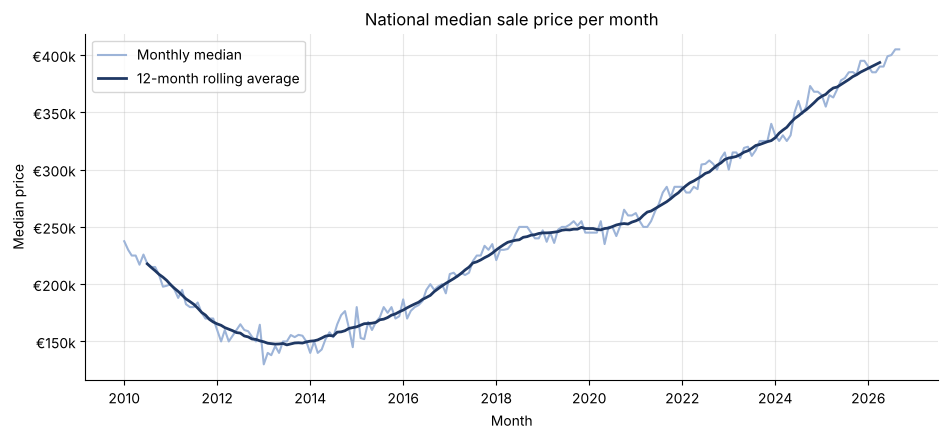

In [18]:
national["rolling_12m"] = national["median_price"].rolling(12, center=True).mean()

fig, ax = plt.subplots()
ax.plot(national["month"], national["median_price"], color="#9DB4D8", label="Monthly median")
ax.plot(national["month"], national["rolling_12m"], color="#1F3864", linewidth=2,
        label="12-month rolling average")
format_euro_axis(ax)
ax.set_title("National median sale price per month")
ax.set_xlabel("Month")
ax.set_ylabel("Median price")
ax.legend()
plt.show()

In [19]:
yearly = df.groupby(df["date_of_sale"].dt.year)["price_eur"].median()
low_year = yearly.idxmin()

print(f"2010 median:   €{yearly.loc[2010]:,.0f}")
print(f"Lowest median: €{yearly.min():,.0f} in {low_year}")
print(f"2026 median:   €{yearly.iloc[-1]:,.0f}")
print(f"Change from lowest point to 2026: {yearly.iloc[-1] / yearly.min() - 1:+.0%}")

2010 median:   €215,650
Lowest median: €150,000 in 2013
2026 median:   €395,000
Change from lowest point to 2026: +163%


**Observation.** The national trend has two clear phases. Prices fell after the 2008 crash and bottomed out in 2013, with a yearly median about 30% below 2010. They then rose steadily, more than doubling (+163%) by 2026. The rise is not perfectly smooth: growth flattened in 2019–2020 and picked up again from 2021. A single straight line cannot describe both the fall and the rise, which is why polynomial features will be tried in the modelling stage.

### 5.2 Prices by county

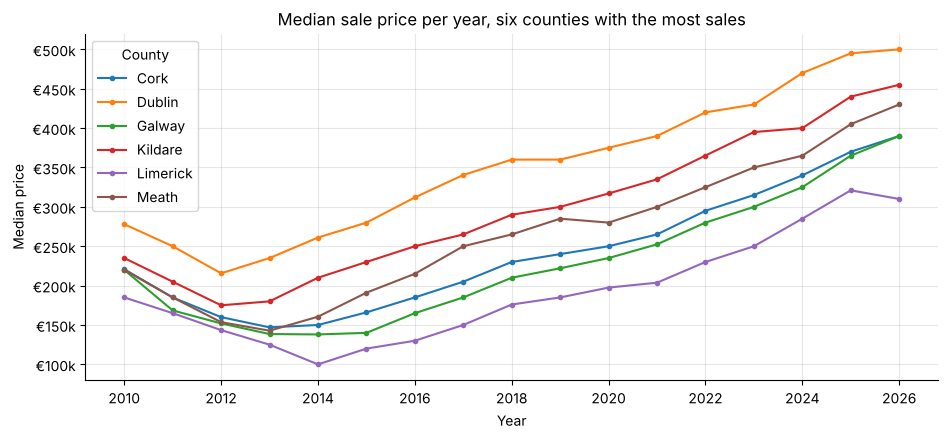

In [20]:
TOP_COUNTIES = df["county"].value_counts().head(6).index.tolist()

county_yearly = (df[df["county"].isin(TOP_COUNTIES)]
                 .groupby([df["date_of_sale"].dt.year, "county"])["price_eur"]
                 .median()
                 .unstack())

fig, ax = plt.subplots()
county_yearly.plot(ax=ax, marker="o", markersize=3)
format_euro_axis(ax)
ax.set_title("Median sale price per year, six counties with the most sales")
ax.set_xlabel("Year")
ax.set_ylabel("Median price")
ax.legend(title="County")
plt.show()

In [21]:
county_change = pd.DataFrame({
    "median_2013": county_yearly.loc[2013],
    "median_2026": county_yearly.loc[county_yearly.index.max()],
})
county_change["growth"] = county_change["median_2026"] / county_change["median_2013"] - 1
county_change.sort_values("growth", ascending=False).style.format(
    {"median_2013": "€{:,.0f}", "median_2026": "€{:,.0f}", "growth": "{:+.0%}"})

,median_2013,median_2026,growth
county,,,
Meath,"€142,755","€430,000",+201%
Galway,"€138,500","€390,000",+182%
Cork,"€147,000","€390,000",+165%
Kildare,"€180,000","€455,000",+153%
Limerick,"€125,000","€310,000",+148%
Dublin,"€235,000","€500,000",+113%


**Observation.** All six counties follow the same overall shape (a fall to 2012–2014, then a steady rise), but at very different levels. Dublin is the most expensive every year, yet it grew the **least** in percentage terms since 2013, while Meath roughly tripled. Counties close to Dublin (Meath, Kildare) have caught up. Because the counties grew at different rates, the county-level models in the next stage will need a separate trend for each county. Note that 2026 is a partial year, so its values (e.g. Limerick's apparent drop) are less reliable.

### 5.3 New versus second-hand homes

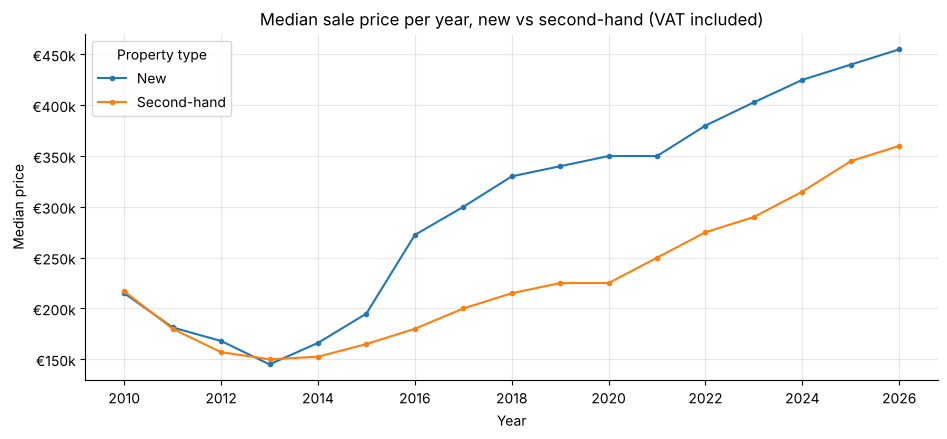

New-home premium over second-hand, by year:
date_of_sale
2010     -1%
2011     +1%
2012     +7%
2013     -3%
2014     +9%
2015    +18%
2016    +51%
2017    +50%
2018    +53%
2019    +51%
2020    +56%
2021    +40%
2022    +38%
2023    +39%
2024    +35%
2025    +28%
2026    +26%


In [22]:
type_yearly = (df.groupby([df["date_of_sale"].dt.year, "property_type"])["price_eur"]
                 .median()
                 .unstack())

fig, ax = plt.subplots()
type_yearly.plot(ax=ax, marker="o", markersize=3)
format_euro_axis(ax)
ax.set_title("Median sale price per year, new vs second-hand (VAT included)")
ax.set_xlabel("Year")
ax.set_ylabel("Median price")
ax.legend(title="Property type")
plt.show()

premium = type_yearly["New"] / type_yearly["Second-hand"] - 1
print("New-home premium over second-hand, by year:")
print(premium.map("{:+.0%}".format).to_string())

**Observation.** Up to 2014, new and second-hand homes sold for about the same median price (the premium was between −3% and +9%). From 2015 the gap widened sharply, to about +50% between 2016 and 2020, and has since narrowed to about +26% in 2026. Because of this gap, a change in the mix of new and second-hand sales in a month can shift the national median on its own. This is worth remembering when interpreting the trend. *(Why the gap opened up around 2015 is an open question worth investigating.)*

## 6. Modelling the national trend

### 6.1 Features and the train/test split

Linear regression needs a numeric input. Each month is turned into **time in years since January 2010** (`t`), so January 2010 is `t = 0`, January 2011 is `t = 1`, and so on. The target is the monthly median price.

Because the goal is to forecast the future, the data **must not be shuffled** before splitting. A random split would let the model see months on both sides of the ones it is tested on, which is much easier than real forecasting. Instead, the split is by time:

- **Training set:** January 2010 to December 2023
- **Test set:** January 2024 to September 2026, a period the models never see during training

In [23]:
def add_time_feature(series):
    """Add 't', the time in years since January 2010, to a monthly series."""
    series = series.copy()
    series["t"] = (series["month"] - pd.Timestamp("2010-01-01")).dt.days / 365.25
    return series


national = add_time_feature(national)
train = national[national["month"] < TEST_START]
test = national[national["month"] >= TEST_START]

X_train, y_train = train[["t"]], train["median_price"]
X_test, y_test = test[["t"]], test["median_price"]

print(f"Training: {len(train)} months ({train['month'].min():%b %Y} to {train['month'].max():%b %Y})")
print(f"Test:     {len(test)} months ({test['month'].min():%b %Y} to {test['month'].max():%b %Y})")

Training: 168 months (Jan 2010 to Dec 2023)
Test:     33 months (Jan 2024 to Sep 2026)


### 6.2 How models are evaluated

Each model is scored on the test period with four metrics:

| Metric | Meaning |
|---|---|
| **RMSE** | Root mean squared error in euro. Penalises large errors heavily. |
| **MAE** | Mean absolute error in euro. The typical size of an error. |
| **MAPE** | Mean absolute percentage error. The typical error as a % of the price. |
| **R²** | How much of the variation *within the test period* the model explains. 1 is perfect. 0 is no better than predicting the test period's own average, and it can be negative. |

R² needs care here. The test period is short (33 months) and prices in it only range from about €325k to €405k, so even a small forecast error gives a low or negative R². RMSE, MAE and MAPE are the main measures, and R² is reported for completeness.

In [24]:
RESULTS = {}  # model name -> scores (re-running a cell replaces its row)

def evaluate(name, y_true, y_pred):
    """Score a forecast on the test period and store it in RESULTS."""
    RESULTS[name] = {
        "RMSE": mean_squared_error(y_true, y_pred) ** 0.5,
        "MAE": mean_absolute_error(y_true, y_pred),
        "MAPE": mean_absolute_percentage_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
    }


def results_table():
    """Show the results collected so far, best (lowest RMSE) first."""
    return (pd.DataFrame(RESULTS).T.sort_values("RMSE")
              .style.format({"RMSE": "€{:,.0f}", "MAE": "€{:,.0f}",
                             "MAPE": "{:.1%}", "R2": "{:.2f}"}))


def plot_forecasts(forecasts, title):
    """Plot actual monthly medians with one or more model forecasts."""
    fig, ax = plt.subplots()
    ax.plot(national["month"], national["median_price"], color="#9DB4D8", label="Actual")
    ax.axvline(pd.Timestamp(TEST_START), color="grey", linestyle="--", linewidth=1)
    ax.text(pd.Timestamp(TEST_START), ax.get_ylim()[1], "  test period", va="top", color="grey")
    for label, predictions in forecasts.items():
        ax.plot(national["month"], predictions, linewidth=2, label=label)
    format_euro_axis(ax)
    ax.set_title(title)
    ax.set_xlabel("Month")
    ax.set_ylabel("Median price")
    ax.legend()
    plt.show()

### 6.3 Baseline: no model

A forecast is only useful if it beats a naive guess. The baseline assumes prices **stay where they were**: the average of the last 12 training months (2023) is predicted for every test month.

In [25]:
baseline_value = train["median_price"].iloc[-12:].mean()
baseline_pred = np.full(len(test), baseline_value)
evaluate("Baseline (2023 average)", y_test, baseline_pred)
print(f"Baseline forecast: €{baseline_value:,.0f} for every test month")

Baseline forecast: €318,583 for every test month


### 6.4 Simple linear regression

The first model is a straight line, `price = a × t + b`, fitted to the whole training period. This is the same model as at the start of the lecture notebook.

Slope:     €10,990 per year
Intercept: €141,770 (fitted value in Jan 2010)
R² on training data: 0.69


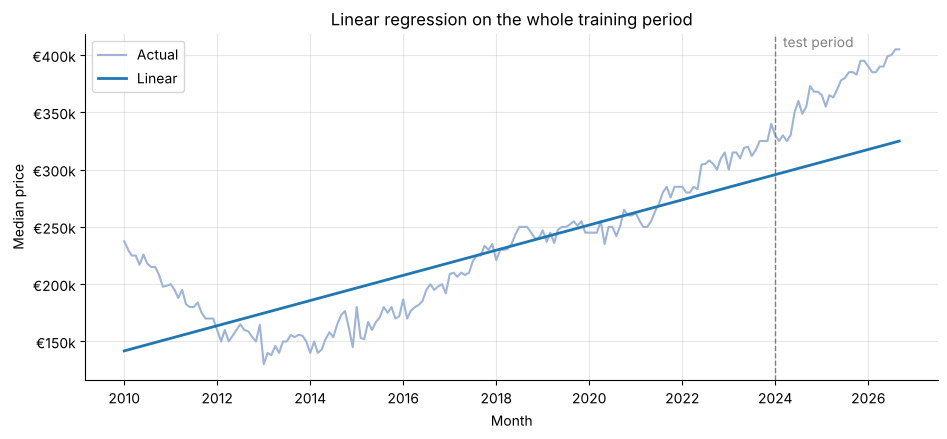

In [26]:
linear = LinearRegression()
linear.fit(X_train, y_train)
evaluate("Linear", y_test, linear.predict(X_test))

print(f"Slope:     €{linear.coef_[0]:,.0f} per year")
print(f"Intercept: €{linear.intercept_:,.0f} (fitted value in Jan 2010)")
print(f"R² on training data: {linear.score(X_train, y_train):.2f}")

plot_forecasts({"Linear": linear.predict(national[["t"]])}, "Linear regression on the whole training period")

**Observation.** A straight line can't follow the fall from 2010 to 2013 and the rise afterwards. It cuts through the middle, so it is too high in the early years and too low at the end. In the test period it underestimates prices badly, which makes it worse than the baseline.

### 6.5 Polynomial regression and overfitting

As in the lecture notebook, `PolynomialFeatures` turns `t` into `t, t², t³, …` so that a linear model can fit a curve. The features are standardised (`StandardScaler`) because `t⁷` is millions of times larger than `t`, which causes numerical problems.

The question is which **degree** to use. The table below fits degrees 1 to 7 and compares how well each fits the training data against how well it forecasts the test period.

In [27]:
def polynomial_model(degree, regressor=None):
    """Pipeline: polynomial features -> standardise -> linear model."""
    regressor = regressor if regressor is not None else LinearRegression()
    return make_pipeline(PolynomialFeatures(degree, include_bias=False), StandardScaler(), regressor)


degree_rows = []
poly_predictions = {}
for degree in [1, 2, 3, 4, 5, 7]:
    model = polynomial_model(degree).fit(X_train, y_train)
    test_pred = model.predict(X_test)
    poly_predictions[degree] = model.predict(national[["t"]])
    degree_rows.append({
        "degree": degree,
        "train R²": model.score(X_train, y_train),
        "test RMSE": mean_squared_error(y_test, test_pred) ** 0.5,
    })

pd.DataFrame(degree_rows).set_index("degree").style.format({"train R²": "{:.3f}", "test RMSE": "€{:,.0f}"})

,train R²,test RMSE
degree,,
1,0.694,"€62,349"
2,0.879,"€27,290"
3,0.945,"€76,587"
4,0.972,"€56,757"
5,0.975,"€159,917"
7,0.981,"€426,496"


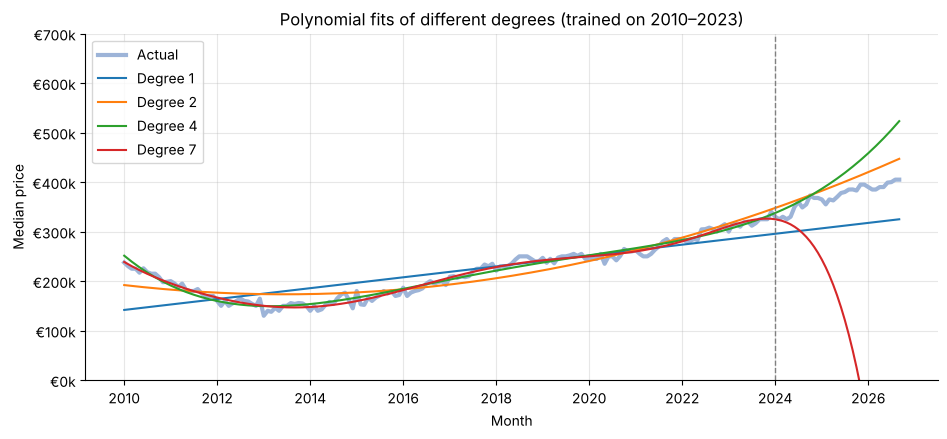

In [28]:
fig, ax = plt.subplots()
ax.plot(national["month"], national["median_price"], color="#9DB4D8", linewidth=3, label="Actual")
for degree in [1, 2, 4, 7]:
    ax.plot(national["month"], poly_predictions[degree], label=f"Degree {degree}")
ax.axvline(pd.Timestamp(TEST_START), color="grey", linestyle="--", linewidth=1)
ax.set_ylim(0, 700_000)
format_euro_axis(ax)
ax.set_title("Polynomial fits of different degrees (trained on 2010–2023)")
ax.set_xlabel("Month")
ax.set_ylabel("Median price")
ax.legend()
plt.show()

**Observation: this is overfitting.** As the degree increases, the **training** fit keeps improving (train R² rises towards 1), but the **test** error does not follow. Above degree 2 the forecasts swing wildly once they leave the training period. Degree 7 fits 2010–2023 best of all and forecasts worst. A high-degree polynomial bends to follow small wiggles in the training data, and nothing controls what it does beyond the last training point. This is the behaviour described in the *Regularization* section of the lecture notebook.

Degree 2 (a parabola) matches the U shape and forecasts best of the unregularised models.

In [29]:
quadratic = polynomial_model(2).fit(X_train, y_train)
evaluate("Polynomial (degree 2)", y_test, quadratic.predict(X_test))

### 6.6 Choosing settings fairly: time-series cross-validation

Choosing the degree by looking at the test results would be cheating, because the test set would then be part of training. Instead, settings are chosen using only the training data, with **time-series cross-validation** (`TimeSeriesSplit`). The training period is cut into 5 folds. Each fold trains on the earlier months and validates on the months straight after, which copies the real forecasting task.

In [30]:
tscv = TimeSeriesSplit(n_splits=CV_SPLITS)

cv_rows = []
for train_idx, val_idx in tscv.split(X_train):
    cv_rows.append({
        "trains on": f"{train['month'].iloc[train_idx[0]]:%b %Y} – {train['month'].iloc[train_idx[-1]]:%b %Y}",
        "validates on": f"{train['month'].iloc[val_idx[0]]:%b %Y} – {train['month'].iloc[val_idx[-1]]:%b %Y}",
    })
pd.DataFrame(cv_rows, index=pd.RangeIndex(1, CV_SPLITS + 1, name="fold"))

,trains on,validates on
fold,,
1,Jan 2010 – Apr 2012,May 2012 – Aug 2014
2,Jan 2010 – Aug 2014,Sep 2014 – Dec 2016
3,Jan 2010 – Dec 2016,Jan 2017 – Apr 2019
4,Jan 2010 – Apr 2019,May 2019 – Aug 2021
5,Jan 2010 – Aug 2021,Sep 2021 – Dec 2023


### 6.7 Ridge and Lasso regularisation

Regularisation adds a penalty for large coefficients, which stops a polynomial from bending too much (see the lecture notebook):

- **Ridge (L2)** penalises the sum of squared coefficients and shrinks all of them.
- **Lasso (L1)** penalises the sum of absolute coefficients and can set some to exactly zero.

The strength of the penalty is set by `alpha`. Both the degree and `alpha` are chosen by `GridSearchCV` using the time-series folds above, so the test period is never used to make the choice.

Ridge: best degree = 2, alpha = 1, CV RMSE = €40,879


Lasso: best degree = 2, alpha = 1000, CV RMSE = €33,773


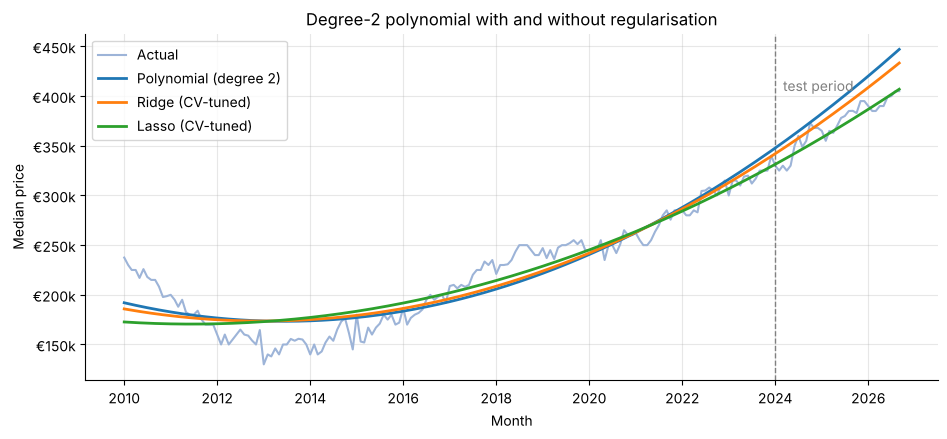

In [31]:
def tune_regularised(regressor, alphas, name):
    """Pick the polynomial degree and alpha with time-series CV, then score on the test set."""
    search = GridSearchCV(
        polynomial_model(2, regressor),
        param_grid={"polynomialfeatures__degree": [2, 3, 4, 5, 6, 7],
                    f"{name}__alpha": alphas},
        cv=tscv,
        scoring="neg_root_mean_squared_error",
    )
    # Some high-degree Lasso candidates don't fully converge. They are never selected,
    # so the warnings are hidden to keep the output readable.
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=ConvergenceWarning)
        search.fit(X_train, y_train)
    best = search.best_params_
    print(f"{name.title()}: best degree = {best['polynomialfeatures__degree']}, "
          f"alpha = {best[name + '__alpha']}, CV RMSE = €{-search.best_score_:,.0f}")
    return search.best_estimator_


ridge = tune_regularised(Ridge(), [0.01, 0.1, 1, 10, 100], "ridge")
lasso = tune_regularised(Lasso(max_iter=100_000, tol=1e-3), [1, 10, 100, 1_000, 3_000], "lasso")

evaluate("Ridge (CV-tuned)", y_test, ridge.predict(X_test))
evaluate("Lasso (CV-tuned)", y_test, lasso.predict(X_test))

plot_forecasts({"Polynomial (degree 2)": quadratic.predict(national[["t"]]),
                "Ridge (CV-tuned)": ridge.predict(national[["t"]]),
                "Lasso (CV-tuned)": lasso.predict(national[["t"]])},
               "Degree-2 polynomial with and without regularisation")

In [32]:
coefficients = pd.DataFrame({
    "No penalty": quadratic[-1].coef_,
    "Ridge": ridge[-1].coef_,
    "Lasso": lasso[-1].coef_,
}, index=["t (scaled)", "t² (scaled)"])
coefficients.style.format("{:,.0f}")

,No penalty,Ridge,Lasso
t (scaled),"-43,686","-33,230","-11,900"
t² (scaled),"91,024","80,426","59,260"


**Observation.** Cross-validation picked degree 2 for both models, and the penalty shrinks the coefficients compared with the unpenalised fit. Because the penalty limits how sharply the curve can bend upwards, the regularised models extrapolate more cautiously, and their test errors are lower than the plain degree-2 polynomial. This shows regularisation working as the lecture notebook describes: a slightly worse fit to the training data (the Lasso curve misses the high prices of 2010) in exchange for better behaviour on unseen data.

### 6.8 A model based on domain knowledge: growth since the recovery

The exploratory analysis showed that the market changed direction around 2013. Prices before that belong to a different phase (the post-crash fall), so a model that only needs to forecast the *current* phase can ignore them. House prices also tend to grow by a **percentage** each year, not a fixed amount in euro, which means growth is exponential:

$$\text{price} = A \times (1 + g)^t \quad\Longrightarrow\quad \log(\text{price}) = \log A + t \log(1 + g)$$

Taking the log of the price turns this into a straight line, so ordinary **linear regression on log(price)** can fit it, using training data from January 2014 to December 2023. The slope gives the yearly growth rate `g`. The 2014 start date comes from the training data (Section 5.1), not from the test results.

Estimated growth rate 2014–2023: 8.0% per year


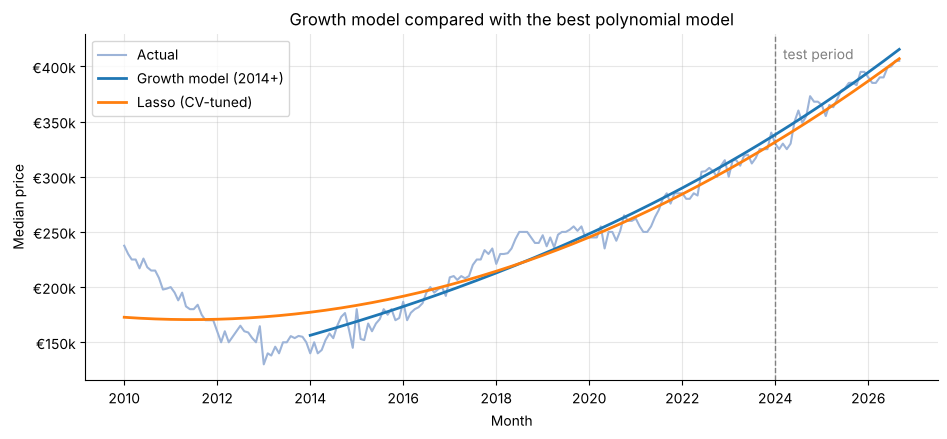

In [33]:
def fit_growth_model(series):
    """Fit log(price) = a*t + b on the recovery period and return the model and yearly growth rate."""
    recovery = series[series["month"] >= RECOVERY_START]
    model = LinearRegression().fit(recovery[["t"]], np.log(recovery["median_price"]))
    yearly_growth = np.exp(model.coef_[0]) - 1
    return model, yearly_growth


def predict_growth_model(model, series):
    """Predict prices (in euro) from a model fitted on log(price)."""
    return np.exp(model.predict(series[["t"]]))


growth_model, growth_rate = fit_growth_model(train)
evaluate("Growth model (log-linear, 2014+)", y_test, predict_growth_model(growth_model, test))
print(f"Estimated growth rate 2014–2023: {growth_rate:.1%} per year")

recovery_months = national["month"] >= RECOVERY_START
growth_line = np.where(recovery_months, predict_growth_model(growth_model, national), np.nan)
plot_forecasts({"Growth model (2014+)": growth_line,
                "Lasso (CV-tuned)": lasso.predict(national[["t"]])},
               "Growth model compared with the best polynomial model")

### 6.9 Gaussian basis functions

The lecture notebook also shows **Gaussian basis functions**. Instead of powers of `t`, the input is replaced by a set of bell-shaped curves spread evenly across the training period, and linear regression finds the weight of each curve. The transformer below is the `GaussianFeatures` class from the lecture notebook (VanderPlas, 2016).

In [34]:
class GaussianFeatures(BaseEstimator, TransformerMixin):
    """Uniformly spaced Gaussian features for one-dimensional input.
    From VanderPlas (2016), Python Data Science Handbook, 'In Depth: Linear Regression'."""

    def __init__(self, N, width_factor=2.0):
        self.N = N
        self.width_factor = width_factor

    @staticmethod
    def _gauss_basis(x, y, width, axis=None):
        arg = (x - y) / width
        return np.exp(-0.5 * np.sum(arg ** 2, axis))

    def fit(self, X, y=None):
        # create N centres spread along the data range
        self.centers_ = np.linspace(X.min(), X.max(), self.N)
        self.width_ = self.width_factor * (self.centers_[1] - self.centers_[0])
        return self

    def transform(self, X):
        return self._gauss_basis(X[:, :, np.newaxis], self.centers_, self.width_, axis=1)

In [35]:
gauss_rows = []
gauss_predictions = {}
for n_bases in [5, 10, 20]:
    model = make_pipeline(GaussianFeatures(n_bases), LinearRegression())
    model.fit(X_train.values, y_train)
    gauss_predictions[n_bases] = model.predict(national[["t"]].values)
    gauss_rows.append({
        "number of bases": n_bases,
        "train R²": model.score(X_train.values, y_train),
        "test RMSE": mean_squared_error(y_test, model.predict(X_test.values)) ** 0.5,
    })

pd.DataFrame(gauss_rows).set_index("number of bases").style.format({"train R²": "{:.3f}", "test RMSE": "€{:,.0f}"})

,train R²,test RMSE
number of bases,,
5,0.978,"€69,110"
10,0.984,"€254,076"
20,0.985,"€930,226"


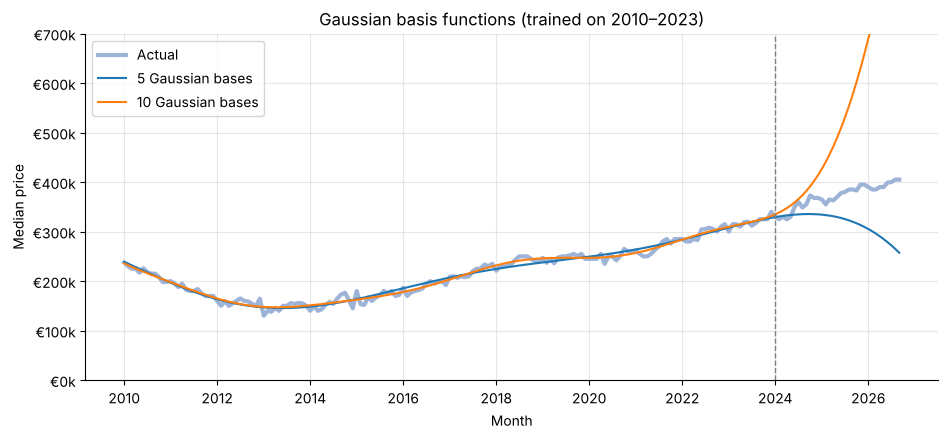

In [36]:
fig, ax = plt.subplots()
ax.plot(national["month"], national["median_price"], color="#9DB4D8", linewidth=3, label="Actual")
for n_bases in [5, 10]:
    ax.plot(national["month"], gauss_predictions[n_bases], label=f"{n_bases} Gaussian bases")
ax.axvline(pd.Timestamp(TEST_START), color="grey", linestyle="--", linewidth=1)
ax.set_ylim(0, 700_000)
format_euro_axis(ax)
ax.set_title("Gaussian basis functions (trained on 2010–2023)")
ax.set_xlabel("Month")
ax.set_ylabel("Median price")
ax.legend()
plt.show()

**Observation.** Gaussian bases fit the training period better than any model so far (train R² above 0.97), including the fall and rise and smaller bumps along the way. They are useless for forecasting, though. Each bell curve only covers a short stretch of time around its centre, and there are no centres after December 2023. Beyond the last training point, the forecast is controlled only by the tails of the last few curves, so it drifts away from reality and becomes more extreme as more bases are added.

This makes a useful point: Gaussian bases are good for **interpolation** (describing the shape of data inside the range already seen) and poor for **extrapolation** (forecasting outside it). They are not added to the results table, because they are not a sensible forecasting model.

### 6.10 Multiple linear regression: adding seasonality

So far every model has used a single input, time. The lecture notebook's bicycle example uses **multiple linear regression**, with several inputs including one 0/1 (dummy) column for each day of the week. The same idea applies here with **month of the year**. The housing market may have a seasonal pattern, so if some months are consistently higher or lower, dummy columns let the model learn this.

First, check whether there is any seasonality: the table shows how far each month's price sits above or below the growth-model trend, on average across the training years.

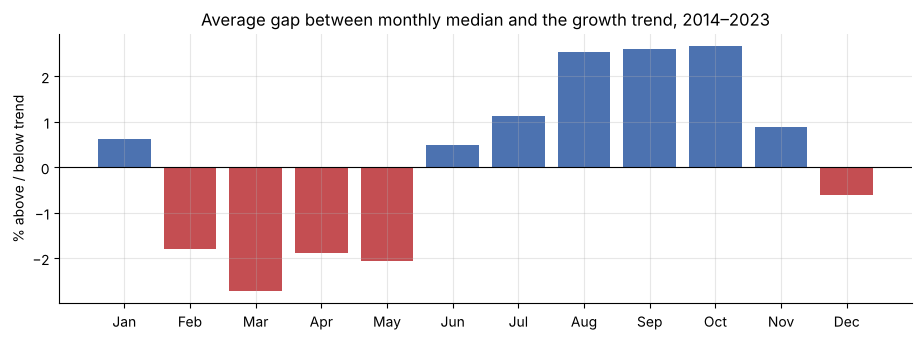

In [37]:
recovery_train = train[train["month"] >= RECOVERY_START]
trend = predict_growth_model(growth_model, recovery_train)
seasonal_gap = (recovery_train["median_price"] / trend - 1).groupby(recovery_train["month"].dt.month).mean()

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.bar(seasonal_gap.index, seasonal_gap.values * 100,
       color=np.where(seasonal_gap.values >= 0, "#4C72B0", "#C44E52"))
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(range(1, 13))
ax.set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_title("Average gap between monthly median and the growth trend, 2014–2023")
ax.set_ylabel("% above / below trend")
plt.show()

There is a clear seasonal pattern: prices recorded in spring (February to May) are typically 2–3% below the trend, and those recorded in late summer and autumn (August to October) are 2–3% above it. Note that the register records the **completion** date of a sale, which usually comes a few months after the price is agreed.

The next model is the growth model from Section 6.8 plus 11 month dummies. January is the reference month and gets no column, so each coefficient measures the difference from January (the same approach as the bicycle example, with one category left out to avoid duplicate information).

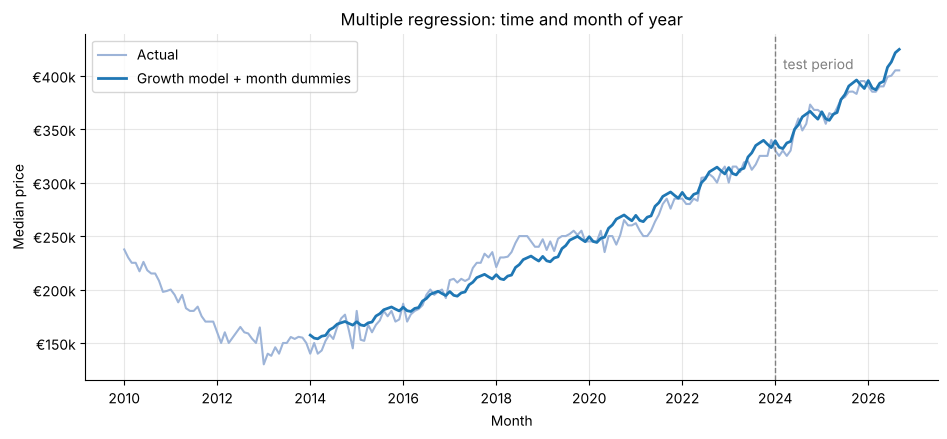

In [38]:
def seasonal_features(series):
    """Time in years plus a 0/1 dummy column for each month (January is the reference)."""
    months = pd.Categorical(series["month"].dt.month, categories=range(1, 13))
    dummies = pd.get_dummies(months, prefix="month", drop_first=True).astype(float)
    dummies.index = series.index
    return pd.concat([series[["t"]], dummies], axis=1)


seasonal_train = train[train["month"] >= RECOVERY_START]
seasonal_model = LinearRegression().fit(seasonal_features(seasonal_train), np.log(seasonal_train["median_price"]))
seasonal_pred = np.exp(seasonal_model.predict(seasonal_features(test)))
evaluate("Growth model + month dummies", y_test, seasonal_pred)

seasonal_line = np.where(recovery_months, np.exp(seasonal_model.predict(seasonal_features(national))), np.nan)
plot_forecasts({"Growth model + month dummies": seasonal_line}, "Multiple regression: time and month of year")

### 6.11 Interpreting the coefficients

Because the model predicts **log(price)**, each coefficient can be turned into a percentage effect with `exp(coefficient) − 1`. This is what the lecture notebook does with the bicycle model: it reads the coefficients as "the effect of one extra unit of this input".

In [39]:
coef_table = pd.DataFrame({
    "coefficient (log scale)": seasonal_model.coef_,
    "effect on price": np.exp(seasonal_model.coef_) - 1,
}, index=seasonal_features(seasonal_train).columns)
coef_table.index = ["t (per year)"] + [f"{m} vs January" for m in
                    ["Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]]
coef_table.style.format({"coefficient (log scale)": "{:+.4f}", "effect on price": "{:+.1%}"})

,coefficient (log scale),effect on price
t (per year),+0.0768,+8.0%
Feb vs January,-0.0245,-2.4%
Mar vs January,-0.0344,-3.4%
Apr vs January,-0.0252,-2.5%
May vs January,-0.0271,-2.7%
Jun vs January,-0.0008,-0.1%
Jul vs January,+0.0049,+0.5%
Aug vs January,+0.0191,+1.9%
Sep vs January,+0.0201,+2.0%
Oct vs January,+0.0207,+2.1%


**How to read this table.**

- **`t`:** holding the month fixed, prices grow by about 8% for each extra year. This matches the time-only growth model, so adding months didn't change the trend estimate.
- **Month dummies:** compared with a January sale in the same year, a sale completed in March is about 3% cheaper and one completed in October about 2% dearer. The difference between the cheapest and dearest months is about 5%, which on a €400,000 home is around €20,000.

**Another feature that does *not* help.** Section 5.3 showed that new homes cost more, so the **share of new homes** in each month's sales could affect the median. The cell below adds it as a third type of input. One caution applies: this uses the actual share of new homes in the test months, which a real forecast wouldn't know in advance, so it is an *explanatory* check, not a fair forecast.

In [40]:
def new_home_share(data):
    """Share of each month's sales that were new homes."""
    is_new = (data["property_type"] == "New").astype(float)
    return is_new.groupby(data["date_of_sale"].dt.to_period("M").dt.to_timestamp()).mean()


share = new_home_share(df)

def features_with_share(series):
    """Seasonal features plus the share of new homes sold that month."""
    features = seasonal_features(series)
    features["new_home_share"] = series["month"].map(share).values
    return features


share_model = LinearRegression().fit(features_with_share(seasonal_train), np.log(seasonal_train["median_price"]))
share_pred = np.exp(share_model.predict(features_with_share(test)))
share_scores = {
    "RMSE": mean_squared_error(y_test, share_pred) ** 0.5,
    "MAPE": mean_absolute_percentage_error(y_test, share_pred),
}
share_effect = np.exp(share_model.coef_[-1] * 0.10) - 1
yearly_share = share.groupby(share.index.year).mean()
print("Share of new homes by year:", ", ".join(f"{y}: {v:.0%}" for y, v in yearly_share.items()))
print(f"Effect of 10 percentage points more new homes: {share_effect:+.1%} on the median")
print(f"Test RMSE with new-home share: €{share_scores['RMSE']:,.0f} (MAPE {share_scores['MAPE']:.1%})")
print(f"Test RMSE without it:          €{RESULTS['Growth model + month dummies']['RMSE']:,.0f} "
      f"(MAPE {RESULTS['Growth model + month dummies']['MAPE']:.1%})")
print(f"Average bias with new-home share: {((share_pred - y_test) / y_test).mean():+.1%} (positive = too high)")

Share of new homes by year: 2010: 26%, 2011: 17%, 2012: 13%, 2013: 12%, 2014: 13%, 2015: 13%, 2016: 14%, 2017: 17%, 2018: 19%, 2019: 19%, 2020: 18%, 2021: 15%, 2022: 17%, 2023: 18%, 2024: 20%, 2025: 22%, 2026: 23%
Effect of 10 percentage points more new homes: +13.0% on the median
Test RMSE with new-home share: €18,360 (MAPE 3.8%)
Test RMSE without it:          €8,143 (MAPE 1.8%)
Average bias with new-home share: +3.6% (positive = too high)


**Observation.** The coefficient makes sense: months with more new homes have a higher median, by roughly 13% for every extra 10 percentage points of new homes. Even with the real test-period values, though, the forecasts get **worse**, and they come out too high. During training, the share of new homes rose (from about 13% in 2014 to 18–19%) at the same time as prices, so the model can't fully separate the effect of the share from the general rise over time. In 2024–2026 the share climbed to 20–23%, higher than in any year of the 2014–2023 training period, and the learned effect pushed the forecasts up too far. Adding a feature only helps if its relationship with the target is stable. For a real forecast the share would also have to be predicted, which adds more uncertainty. This feature is left out of the final models and the results table.

### 6.12 Comparing all models

In [41]:
results_table()

,RMSE,MAE,MAPE,R2
Growth model + month dummies,"€8,143","€6,710",1.8%,0.88
Lasso (CV-tuned),"€8,537","€6,972",1.9%,0.87
"Growth model (log-linear, 2014+)","€9,495","€7,855",2.2%,0.84
Ridge (CV-tuned),"€18,166","€16,007",4.3%,0.40
Polynomial (degree 2),"€27,290","€24,943",6.7%,-0.35
Baseline (2023 average),"€57,112","€52,051",13.7%,-4.90
Linear,"€62,349","€60,377",16.1%,-6.04


In [42]:
scores = pd.DataFrame(RESULTS).T
best_name = scores["RMSE"].idxmin()
best = scores.loc[best_name]
print(f"Best model on the test period: {best_name}")
print(f"Typical error: €{best['MAE']:,.0f} ({best['MAPE']:.1%}) on prices of about €{y_test.mean():,.0f}")

growth_test = predict_growth_model(growth_model, test)
bias = ((growth_test - y_test) / y_test).mean()
print(f"Growth model average bias on test: {bias:+.1%} (positive = forecasts too high)")

Best model on the test period: Growth model + month dummies
Typical error: €6,710 (1.8%) on prices of about €370,635
Growth model average bias on test: +1.4% (positive = forecasts too high)



**Observation.** The best model is the **growth model with month dummies**: linear regression on log(price), using time and month of year, trained on the recovery period (2014–2023). It forecast the 2024–2026 national median with a typical error under 2%, nearly three years ahead. The Lasso polynomial and the plain growth model are close behind. Differences of about €1,000 RMSE are small for a 33-month test period, so the top three are about equally good. All of them easily beat the baseline and the straight line. The unregularised high-degree polynomials (Section 6.5) and the Gaussian bases (Section 6.9) fit the training data best and forecast worst.

The growth models have a practical advantage: their coefficients are easy to explain ("prices grow about 8% a year, and autumn completions are about 2% dearer than January ones") and they give a growth rate that can be compared between counties, which the next section uses.


## 7. County-level models

The same growth model is fitted separately for the six counties with the most sales, using the same training and test periods. This answers the second half of the question: does a single approach work across different markets?

In [43]:
county_rows = []
county_series = {}
for county in TOP_COUNTIES:
    series = add_time_feature(monthly_median(df[df["county"] == county]))
    county_series[county] = series
    county_train = series[series["month"] < TEST_START]
    county_test = series[series["month"] >= TEST_START]

    model, growth = fit_growth_model(county_train)
    predictions = predict_growth_model(model, county_test)
    county_rows.append({
        "county": county,
        "growth per year (2014–23)": growth,
        "test MAE": mean_absolute_error(county_test["median_price"], predictions),
        "test MAPE": mean_absolute_percentage_error(county_test["median_price"], predictions),
        "bias": ((predictions - county_test["median_price"]) / county_test["median_price"]).mean(),
        "sales per month": county_test["sales"].mean(),
    })

county_results = pd.DataFrame(county_rows).set_index("county").sort_values("test MAPE")
county_results.style.format({"growth per year (2014–23)": "{:.1%}", "test MAE": "€{:,.0f}",
                             "test MAPE": "{:.1%}", "bias": "{:+.1%}", "sales per month": "{:,.0f}"})

,growth per year (2014–23),test MAE,test MAPE,bias,sales per month
county,,,,,
Dublin,5.5%,"€10,961",2.3%,+1.0%,"1,470"
Cork,8.3%,"€10,247",2.9%,+2.3%,535
Kildare,6.9%,"€13,218",3.2%,+2.4%,262
Galway,9.4%,"€13,579",4.0%,+2.9%,210
Limerick,10.1%,"€17,884",5.8%,+1.1%,163
Meath,8.2%,"€27,495",7.2%,+7.2%,210


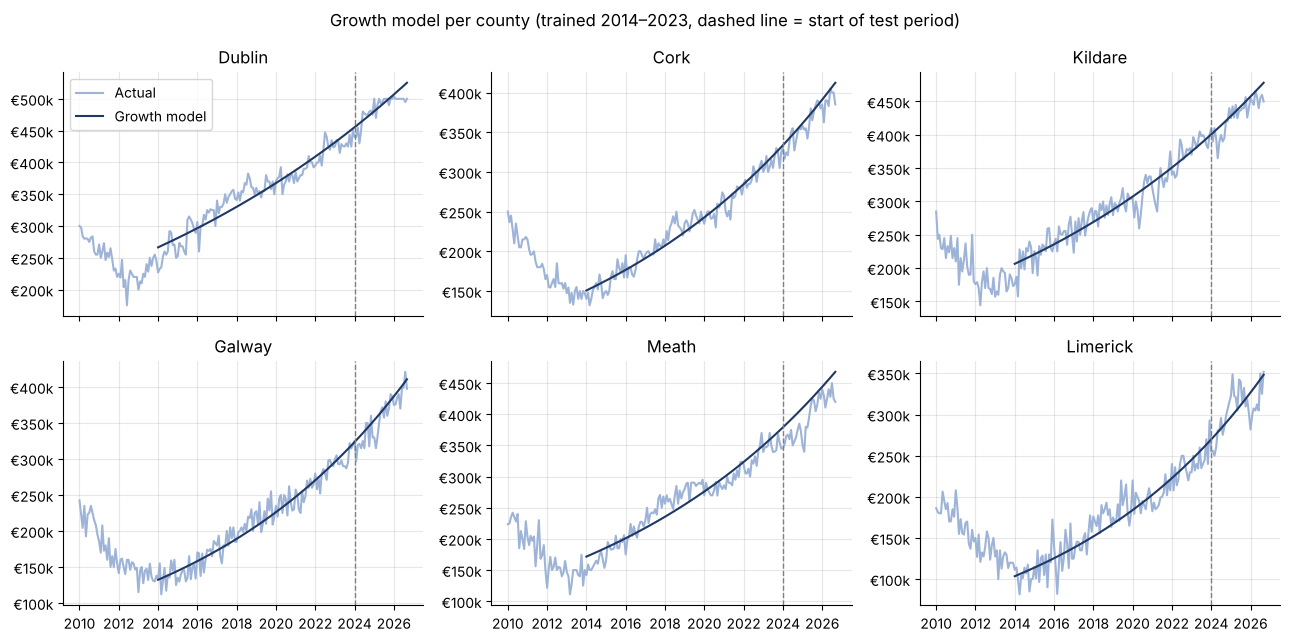

In [44]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5), sharex=True)
for ax, county in zip(axes.flat, TOP_COUNTIES):
    series = county_series[county]
    model, _ = fit_growth_model(series[series["month"] < TEST_START])
    recovery = series[series["month"] >= RECOVERY_START]
    ax.plot(series["month"], series["median_price"], color="#9DB4D8", label="Actual")
    ax.plot(recovery["month"], predict_growth_model(model, recovery), color="#1F3864", label="Growth model")
    ax.axvline(pd.Timestamp(TEST_START), color="grey", linestyle="--", linewidth=1)
    ax.set_title(county)
    format_euro_axis(ax)
axes.flat[0].legend()
fig.suptitle("Growth model per county (trained 2014–2023, dashed line = start of test period)")
fig.tight_layout()
plt.show()

**Observation.** The growth model works in every county, with typical errors in the test period of a few percent. Estimated growth rates differ a lot, from about 5–6% a year in Dublin to roughly 10% in Limerick, which confirms the county differences seen in Section 5.2. The bias column shows that the model forecasts **too high** in every county, so growth in 2024–2026 was a little slower than the 2014–2023 trend. The errors are larger in counties with fewer sales per month (such as Meath and Limerick), where the monthly median is noisier.

## 8. Deployment

Deployment is the last phase of CRISP-DM. This project is a portfolio analysis, not a live system, but this is how the model could be put to use and kept reliable:

- **How it would be used.** A small tool or dashboard showing the current trend and a 12-month forecast, nationally and per county, for example for buyers planning a purchase or for a lender monitoring the market.
- **Updating.** The PSRA updates the register regularly. A scheduled job would download the latest data, rerun the cleaning steps in Section 4 and refit the growth model. Because every step is a function and all settings are constants at the top of the notebook, the code could be moved into a Python script for this with few changes.
- **Monitoring.** Each month, the forecast would be compared with the actual median. If the error stayed above a threshold (for example 5% for several months), the model would be flagged for review. This would catch a change of trend like the one in 2013.
- **Limits to communicate.** Users would need to know that the model only uses time and season, can't predict shocks, and is based on the median, which is affected by the mix of homes sold.

## 9. Conclusion

**Question.** How well can a regression model trained on past Irish house prices forecast how prices change over time, nationally and by county?

**Answer.** Quite well, for a model this simple, as long as it has the right shape. Trained only on data up to December 2023, the best model (a growth model with month-of-year dummies) forecast the national monthly median for January 2024 to September 2026 with a typical error under 2%. A log-linear growth model fitted to the recovery period also worked for each of the six largest counties, with errors of a few percent.

**What the models showed.**

1. **Model shape matters more than complexity.** A straight line fails because the trend changed direction in 2013. High-degree polynomials fit the past almost perfectly but produce nonsense forecasts. This is overfitting.
2. **Regularisation helps.** Ridge and Lasso, with settings chosen by time-series cross-validation on the training data only, gave clearly better forecasts than the same polynomial without a penalty.
3. **Domain knowledge helps.** Modelling percentage growth (log of price) over the current market phase gave a model that is both accurate and easy to explain. National prices grew by about 8% a year from 2014 to 2023.
4. **Multiple regression helps only with the right features.** Month-of-year dummies captured a seasonal swing of about 5% and improved the forecast. The share of new homes was a sensible feature but made forecasts worse, because its relationship with price wasn't stable.
5. **Not every model suits forecasting.** Gaussian basis functions fit the past best of all but can't extrapolate.
6. **Markets differ.** Growth varied from about 5–6% a year in Dublin to about 10% in Limerick, and every county grew a little more slowly in 2024–2026 than its earlier trend.

**Limitations.**

- These models only use **time**. They can't foresee shocks such as a recession, interest-rate changes or new housing policy. The 2010–2013 crash is a reminder that trends can reverse.
- The median depends on the **mix** of homes sold in a month (for example the share of new homes, Section 5.3), not only on price changes.
- The test period is short (33 months), so the R² values are unstable. The euro and percentage errors are more reliable.
- The 2014 start for the growth model is a judgement based on the exploratory analysis.

**Next steps for the final portfolio.**

- Add outside data that a forecast could actually know in advance, such as interest rates or housing completions (Central Statistics Office).
- Try models covered later in the module and compare them with these results.
- Project 2: UFC fight outcome prediction with engineered pre-fight features (see the specification).


## References

- Property Services Regulatory Authority. *Residential Property Price Register.* Published under section 86 of the Property Services (Regulation) Act 2011. Licensed under CC BY 4.0. https://www.propertypriceregister.ie and https://data.gov.ie/organization/property-services-regulatory-authority
- VanderPlas, J. (2016). *Python Data Science Handbook*, "In Depth: Linear Regression" (source of the `GaussianFeatures` class). https://github.com/jakevdp/PythonDataScienceHandbook
- Berners-Lee, T. *5-star Open Data.* https://5stardata.info
- scikit-learn documentation: `LinearRegression`, `Ridge`, `Lasso`, `PolynomialFeatures`, `TimeSeriesSplit`, `GridSearchCV`. https://scikit-learn.org/stable/
